# 1. Find anterior-posterior (AP) variable genes in spatial transcriptomics data

**Input:** `data/spatial_hpf_data_subset_spatially_variable_genes.h5ad`

**Outputs** (written to `results/`): per-group cluster distribution plots, coronal-section plots, binned-expression heatmaps and GAM-fit gene-cluster plots.

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from pygam import LinearGAM, s
from scipy import sparse
from scipy.cluster import hierarchy

from config import SPATIAL_HPF_H5AD, RESULTS_DIR, set_plot_style

set_plot_style(**{'figure.dpi': 300})

In [2]:
## load spatial transcriptomics data
spatial_data = sc.read_h5ad(SPATIAL_HPF_H5AD)
hpf_groups = ['CA3 Glut', 'CA1-ProS Glut', 'SUB-ProS Glut']
spatial_cluster_col = 'Cluster_v4_label'

## 1. Visualize cluster distribution across Z

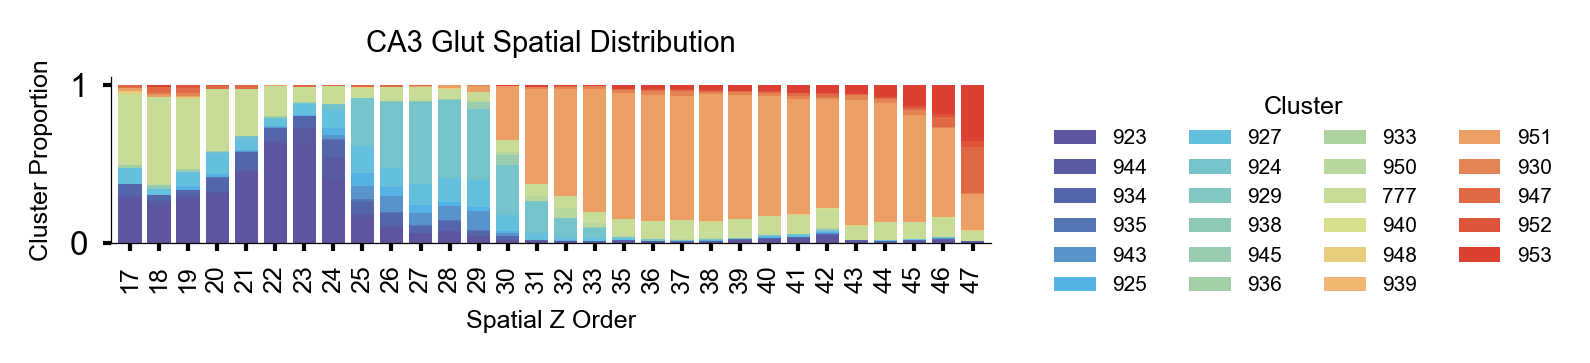

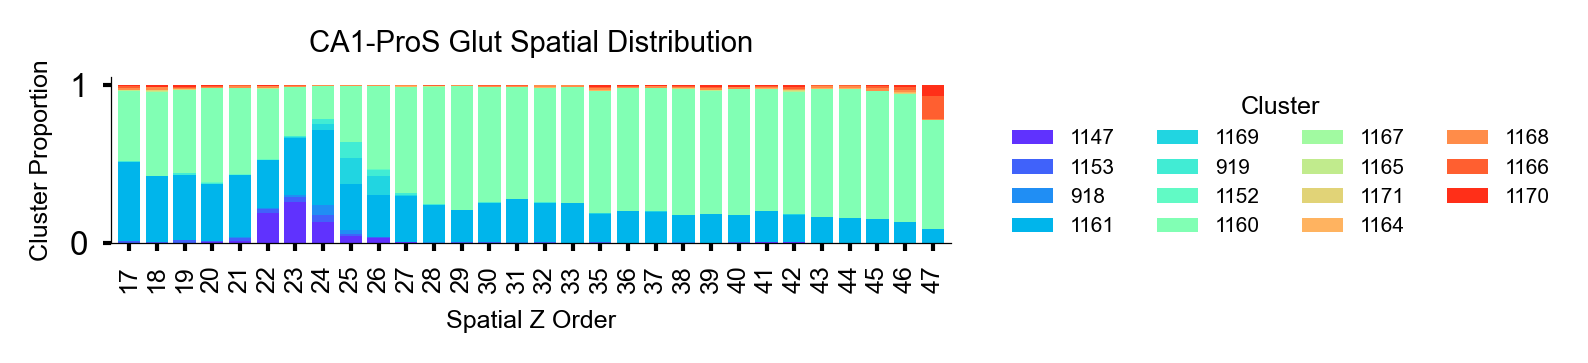

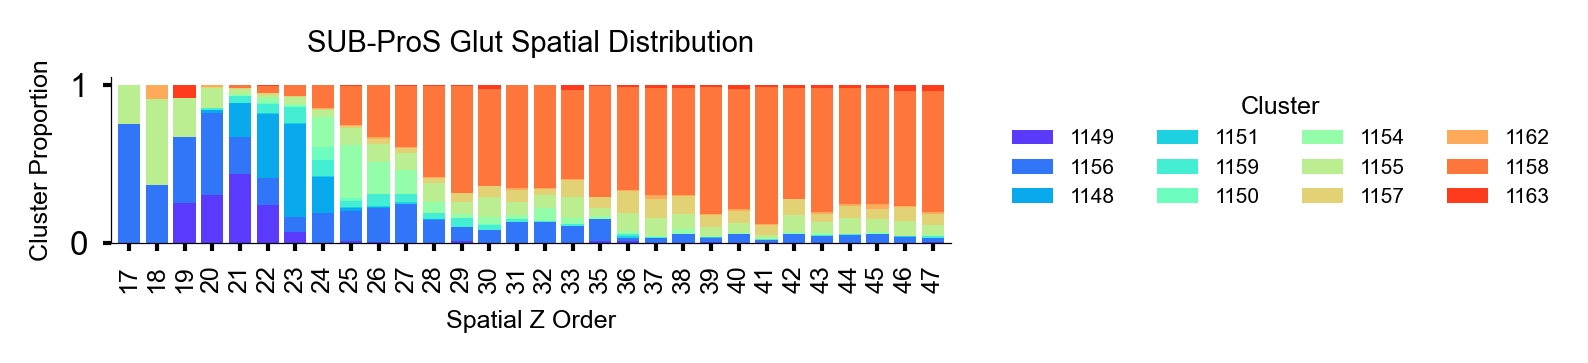

In [3]:
group_cluster_pal = {}
group_cluster_pal['CA3 Glut'] = {
    "cluster_923": "#5e55a0",
    "cluster_944": "#585ba3",
    "cluster_934": "#5465ab",
    "cluster_935": "#5476b6",
    "cluster_943": "#5893cc",
    "cluster_925": "#55b2e5",
    "cluster_927": "#64c0dc",
    "cluster_924": "#76c4cb",
    "cluster_929": "#84c7c1",
    "cluster_938": "#8ec9b8",
    "cluster_945": "#9accaf",
    "cluster_936": "#a3cfa7",
    "cluster_933": "#afd3a0",
    "cluster_950": "#b9d79c",
    "cluster_777": "#c6dc97",
    "cluster_940": "#d7df8d",
    "cluster_948": "#e7cc7d",
    "cluster_939": "#f0b570",
    "cluster_951": "#eb9f64",
    "cluster_930": "#e58453",
    "cluster_947": "#e06945",
    "cluster_952": "#dd543a",
    "cluster_953": "#db4032",
}


for group in hpf_groups:
    ## plot stacked bar with z on x-axis and cluster proportion on y-axis
    spatial_data_group = spatial_data[spatial_data.obs['Subcortex_Group_v4'] == group]
    fig, ax = plt.subplots(1, 1, figsize=(5.5, 1.25))

    plot_data = spatial_data_group.obs[[spatial_cluster_col, 'z_order']].copy()

    # Calculate proportions for each z
    z_cluster_counts = plot_data.groupby(['z_order', spatial_cluster_col], observed=False).size().unstack(fill_value=0)
    z_cluster_props = z_cluster_counts.div(z_cluster_counts.sum(axis=1), axis=0)
    z_cluster_props = z_cluster_props.sort_index()

    # Plot stacked bar
    cluster_modal_z = plot_data.groupby(spatial_cluster_col, observed=False)['z_order'].agg(lambda x: x.mode()[0] if len(x.mode()) > 0 else x.median()).sort_values()
    sorted_clusters = cluster_modal_z.index.tolist()
    z_cluster_props = z_cluster_props[sorted_clusters]
    if group not in group_cluster_pal:
        palette = sns.color_palette('rainbow', n_colors=spatial_data_group.obs[spatial_cluster_col].nunique())
        palette = [palette[list(z_cluster_props.columns).index(cluster)] for cluster in sorted_clusters]

        ## save the color palette for later use
        group_cluster_pal[group] = {cluster: palette[i] for i, cluster in enumerate(sorted_clusters)}
    else:
        desired_order = list(group_cluster_pal[group].keys())
        desired_order = [c for c in desired_order if c in z_cluster_props.columns]
        z_cluster_props = z_cluster_props[desired_order]
        palette = [group_cluster_pal[group][c] for c in desired_order]

    z_cluster_props.plot(kind='bar', stacked=True, ax=ax, color=palette, width=0.8, edgecolor='none')
    ax.set_ylabel('Cluster Proportion', fontsize=6)
    ax.set_xlabel('Spatial Z Order', fontsize=6)
    ax.set_title(f'{group} Spatial Distribution', fontsize=7)
    sns.despine(ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(),  ha='center', fontsize=6)
    handles, labels = ax.get_legend_handles_labels()
    new_labels = [str(l).replace('cluster_', '') for l in labels]
    ax.legend(handles, new_labels, bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=5, ncol=4, frameon=False, title='Cluster', title_fontsize=6)
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / f'{group}_spatial_distribution.svg', transparent=True, format='svg')
    plt.show()

## 2. Visualize on 2D coronal sections

In [4]:
## combined scatter + cluster-proportion bar for each z section
z_plot = ['25', '29', '31', '39', '46']
group = 'CA3 Glut'
cluster_palette = group_cluster_pal[group]
cluster_names = list(cluster_palette.keys())

for z in z_plot:
    # per-section dataframe
    plot_df = pd.DataFrame({
        'x': spatial_data.obs['x'],
        'y': spatial_data.obs['y'],
        'Cluster': spatial_data.obs[spatial_cluster_col],
        'z_order': spatial_data.obs['z_order'].astype(str)
    })
    plot_df = plot_df[plot_df['z_order'] == z]

    # color & size mapping (cells outside the group shown in grey)
    colors = plot_df['Cluster'].map(cluster_palette).fillna('#D3D3D3')
    sizes = np.where(colors == '#D3D3D3', 0.5, 1)

    # small horizontal proportion bar on top, scatter below
    fig, (ax_bar, ax) = plt.subplots(2, 1, figsize=(1.5, 1.7),
                                     gridspec_kw={'height_ratios': [0.1, 1], 'hspace': 0.02})

    ax.scatter(-plot_df['x'], -plot_df['y'], c=colors, s=sizes,
               marker='o', edgecolors='none', rasterized=True)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.tick_params(axis='both', which='both', length=0)
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
    ax.grid(False)

    # proportion bar: only non-grey cells in the denominator
    non_grey_df = plot_df[(colors != '#D3D3D3').values]
    if non_grey_df.empty:
        cluster_counts = pd.Series(dtype=float)
    else:
        cluster_counts = non_grey_df['Cluster'].value_counts(normalize=True)
        cluster_counts = cluster_counts[cluster_counts.index.isin(cluster_names)]

    left = 0.0
    for cluster_name in cluster_names:
        proportion = float(cluster_counts.get(cluster_name, 0.0))
        if proportion > 0:
            ax_bar.barh(0, proportion, left=left, color=cluster_palette[cluster_name])
        left += proportion

    ax_bar.set_xlim(0, 1)
    ax_bar.set_xticks([])
    ax_bar.set_yticks([])
    for spine in ax_bar.spines.values():
        spine.set_visible(False)

    save_path = RESULTS_DIR / f'{group.replace("/", "_").replace(" ", "_")}_spatial_HPF_Cluster_Combined_Z{z}_raw.pdf'
    fig.savefig(save_path, format='pdf', bbox_inches='tight', dpi=600)
    plt.close(fig)

## 3. Find genes variably expressed across Z (std > 0.5)

In [5]:
num_bins = 30
min_cells_per_bin = 10   # bins with fewer cells are ignored
## GAM parameters
n_splines = 6
n_grid_pts = 30

counts_dfs = {}
gam_fits_dfs = {}

for group in hpf_groups:
    spatial_data_group = spatial_data[spatial_data.obs['Subcortex_Group_v4'] == group].copy()
    z = pd.to_numeric(spatial_data_group.obs['z_depth_ap_nominal'], errors='coerce')

    # equal-cell bins along z
    spatial_data_group.obs['z_bin'] = pd.qcut(z, q=num_bins, labels=False, duplicates='drop')
    bin_counts = spatial_data_group.obs['z_bin'].value_counts().sort_index()
    good_bins = bin_counts[bin_counts >= min_cells_per_bin].index.values
    bin_centers = spatial_data_group.obs.groupby('z_bin')['z_depth_ap_nominal'].mean().loc[good_bins].values.astype(float)

    X = spatial_data_group.layers['log2cpt']

    # median expression per bin -> genes x bins matrix
    genes = spatial_data_group.var_names
    binned = np.zeros((len(genes), len(good_bins)), dtype=float)
    for i, b in enumerate(good_bins):
        Xb = X[spatial_data_group.obs['z_bin'].values == b, :]
        if sparse.issparse(Xb):
            Xb = Xb.toarray()
        binned[:, i] = np.median(Xb, axis=0)

    binned_df = pd.DataFrame(binned, index=genes, columns=good_bins)
    row_std = binned_df.std(axis=1, ddof=0)
    binned_df = binned_df.loc[row_std > 0.5, :]
    print(f"  Group {group}: {binned_df.shape[0]} genes are variably expressed across AP bins.")

    # fit a GAM to each variable gene
    GAM_fits_df = pd.DataFrame(np.zeros((binned_df.shape[0], n_grid_pts), dtype=float), index=binned_df.index)
    for gene in binned_df.index:
        ay = binned_df.loc[gene].values
        gam = LinearGAM(s(0, lam=0.6, n_splines=n_splines), fit_intercept=False).fit(bin_centers, ay)
        axx = gam.generate_X_grid(term=0, n=n_grid_pts)
        GAM_fits_df.loc[gene, :] = gam.predict(X=axx)

    counts_dfs[group] = binned_df
    gam_fits_dfs[group] = GAM_fits_df

  Group CA3 Glut: 35 genes are variably expressed across AP bins.
  Group CA1-ProS Glut: 25 genes are variably expressed across AP bins.
  Group SUB-ProS Glut: 28 genes are variably expressed across AP bins.


## 4. Visualize genes variably expressed across Z
- binned expression (scaled per gene)
- GAM-fitted trends, clustered

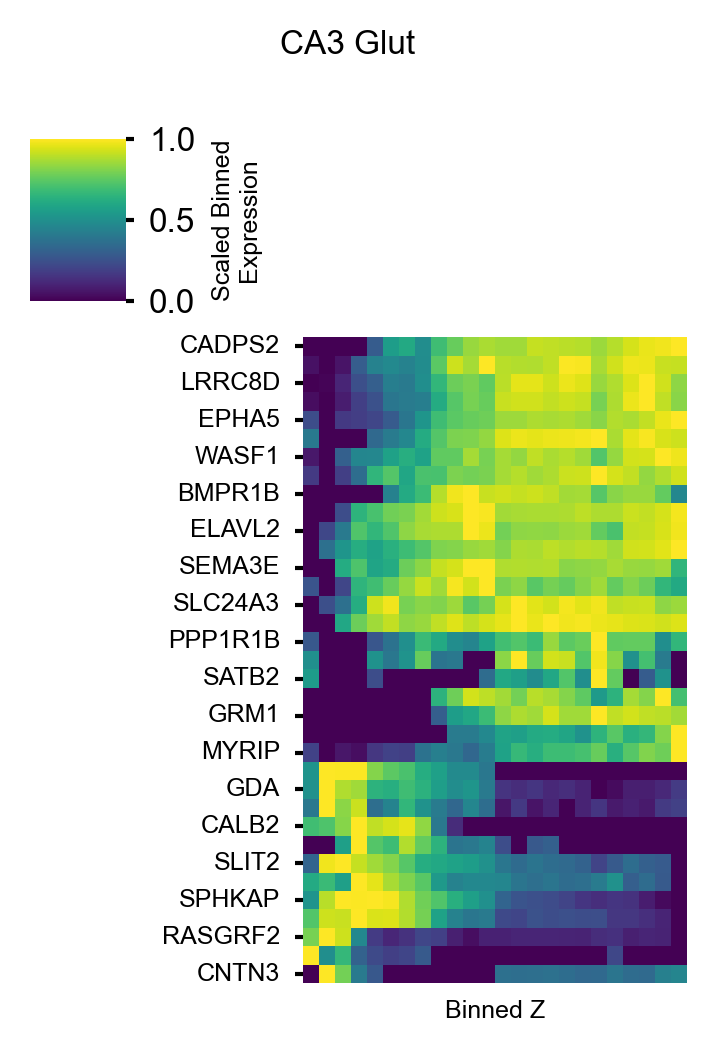

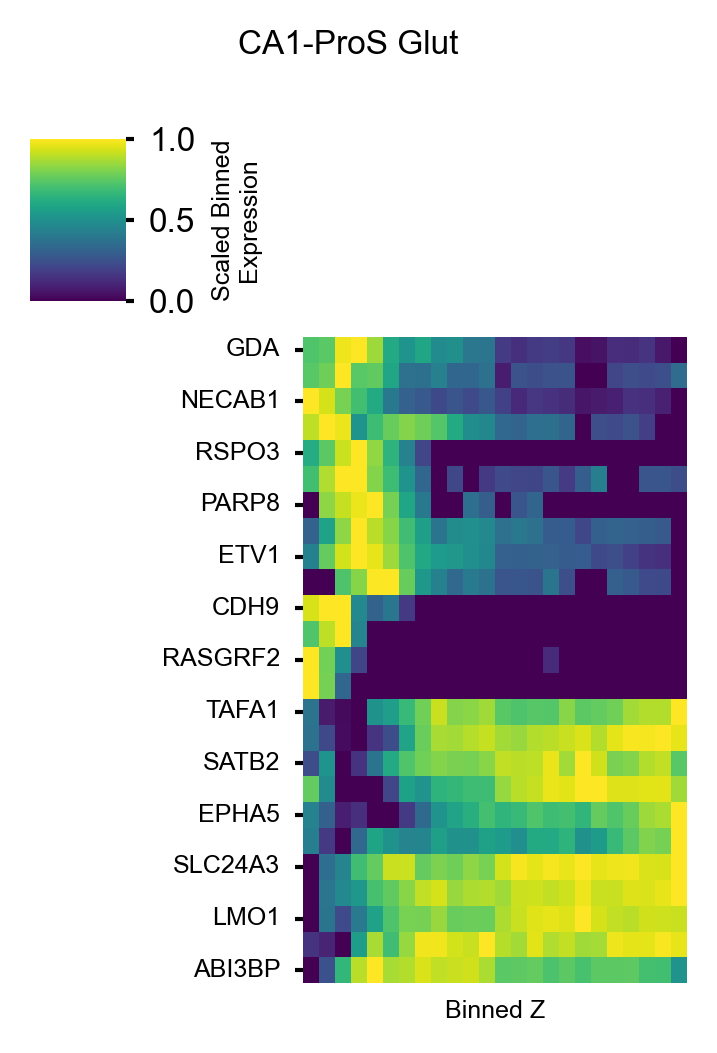

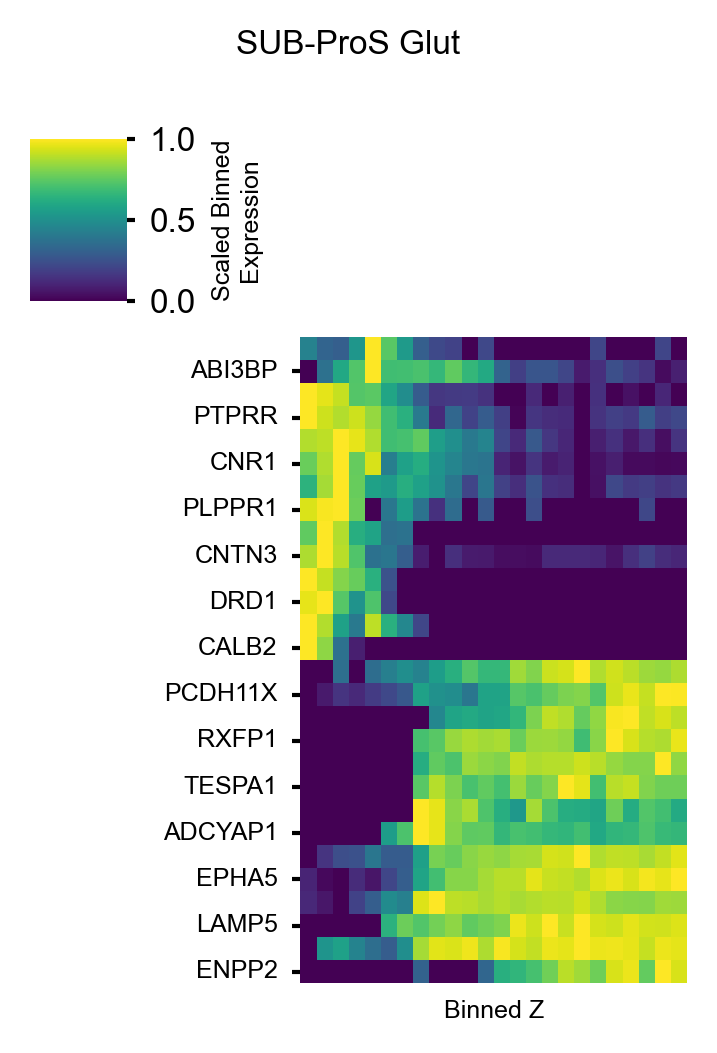

In [6]:
## heatmap of binned expression (scaled per gene)
for group, counts_df in counts_dfs.items():
    ax = sns.clustermap(counts_df, metric='euclidean', method='ward',
                       col_cluster=False, row_cluster=True,cmap = 'viridis',
                       figsize=(2.5,3.5),
                       standard_scale=0,
                       xticklabels=False, yticklabels=True,
                       )
    ax.ax_heatmap.invert_yaxis()
    ax.ax_row_dendrogram.invert_yaxis()
    ax.ax_row_dendrogram.set_visible(False)
    ax.ax_cbar.set_ylabel("Scaled Binned\nExpression", size=6)
    norm_exp = ax.data2d
    ax.ax_heatmap.tick_params(axis='y', left=True, right=False, labelleft=True, labelright=False)
    for i, tick in enumerate(ax.ax_heatmap.yaxis.get_major_ticks()):
        show = (i % 2 == 0)
        tick.label1.set_visible(show)
        tick.label2.set_visible(False)
        tick.tick1line.set_visible(show)
        tick.tick2line.set_visible(False)
        if show:
            tick.label1.set_fontsize(6)

    ax.ax_heatmap.set_ylabel('')
    ax.ax_heatmap.set_xlabel('Binned Z', fontsize=6)
    plt.suptitle(f'{group}', fontsize=8)
    plt.tight_layout()
    ax.savefig(RESULTS_DIR / f'{group}_binned_expression_log2cpt.svg', format='svg', bbox_inches='tight', transparent=True, dpi=400)

Clustering GAM fits for group: CA3 Glut
Number of gene clusters: 2


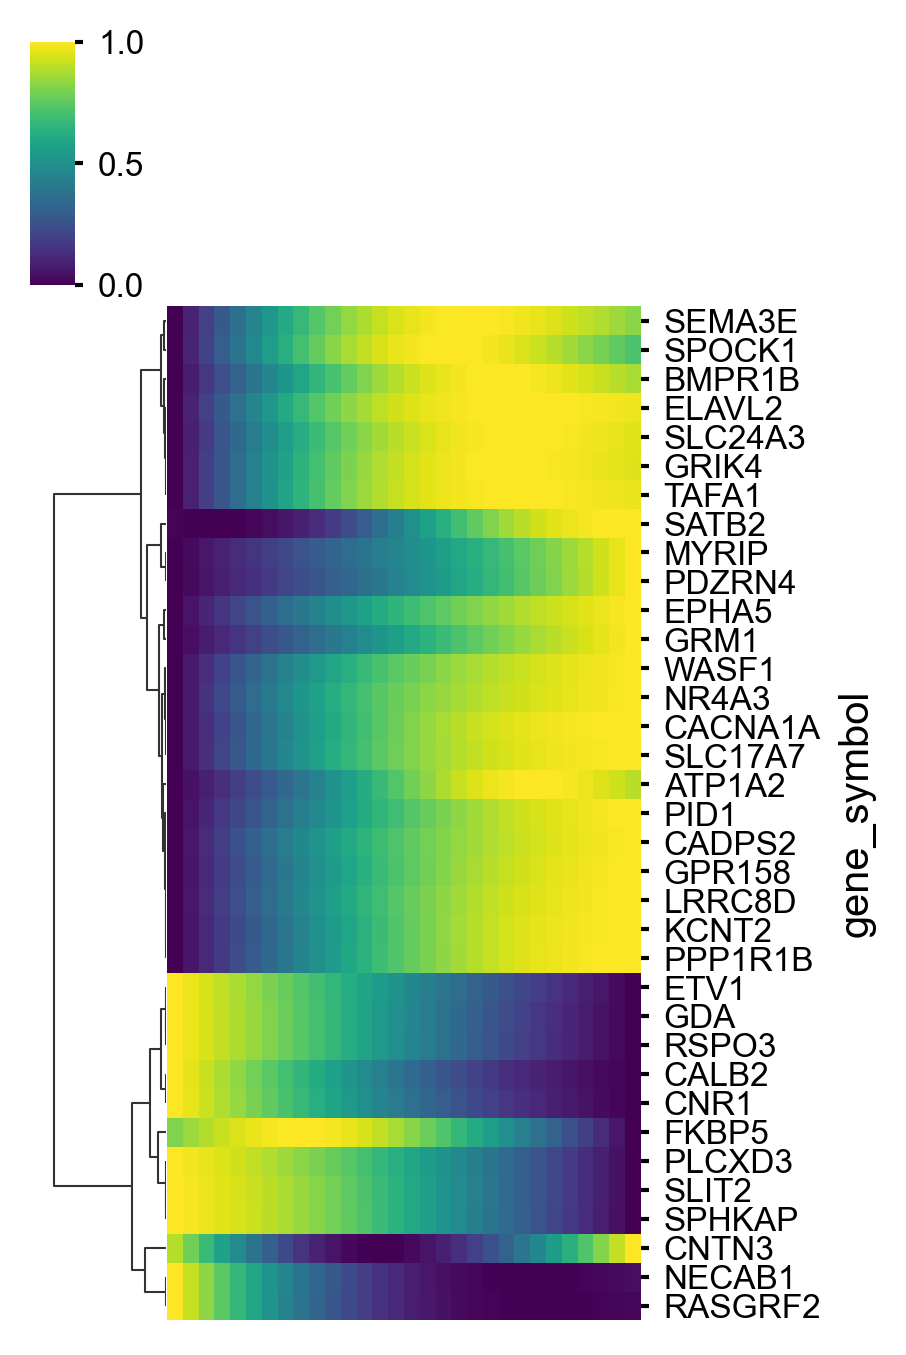

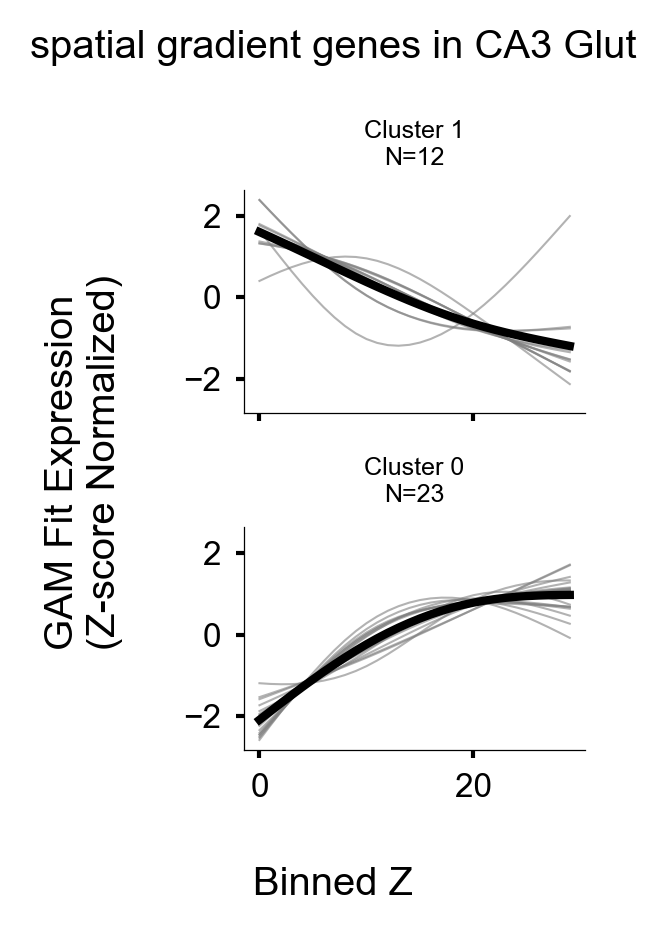

Clustering GAM fits for group: CA1-ProS Glut
Number of gene clusters: 2


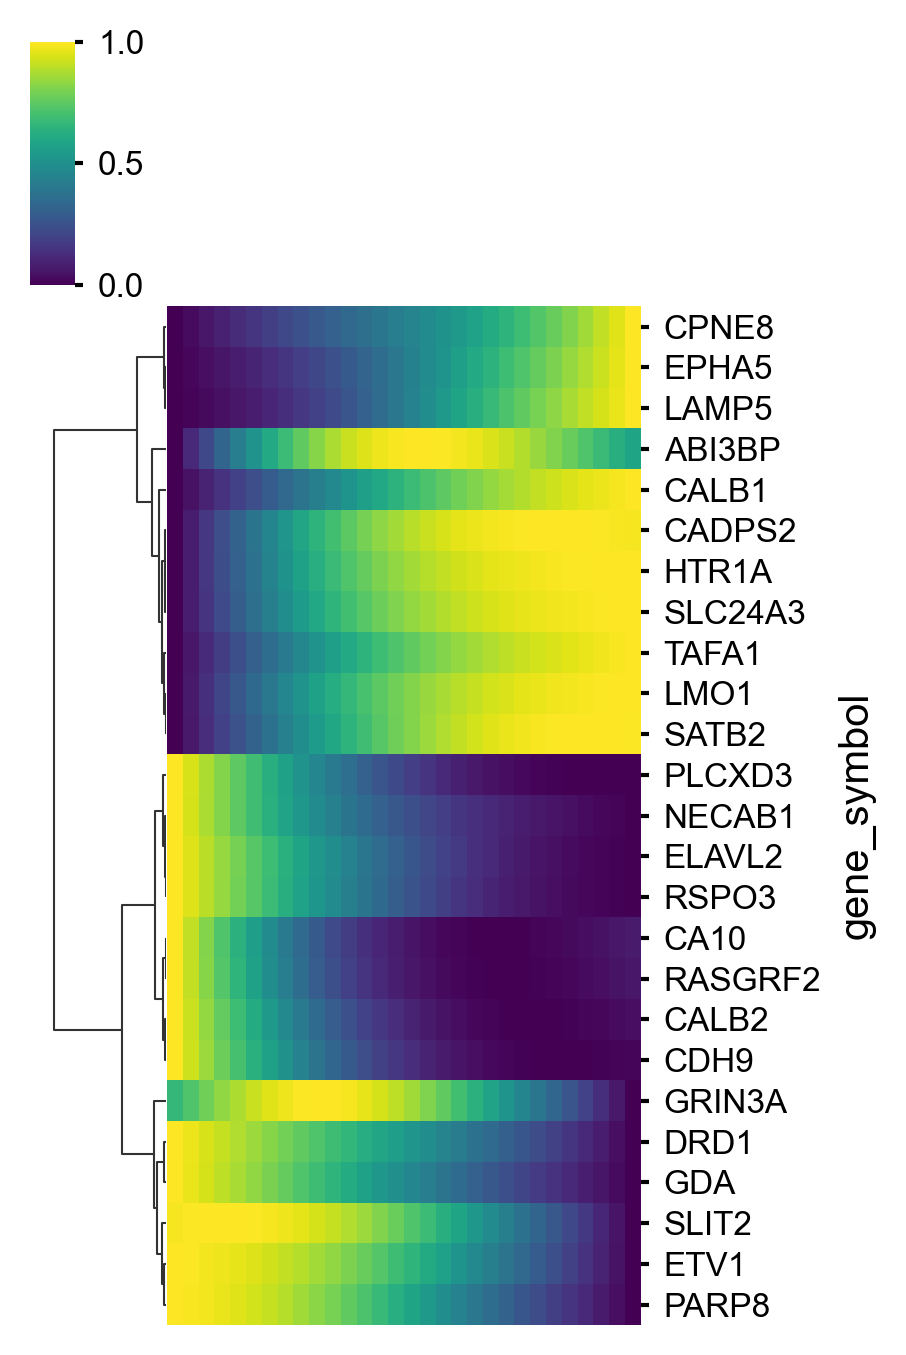

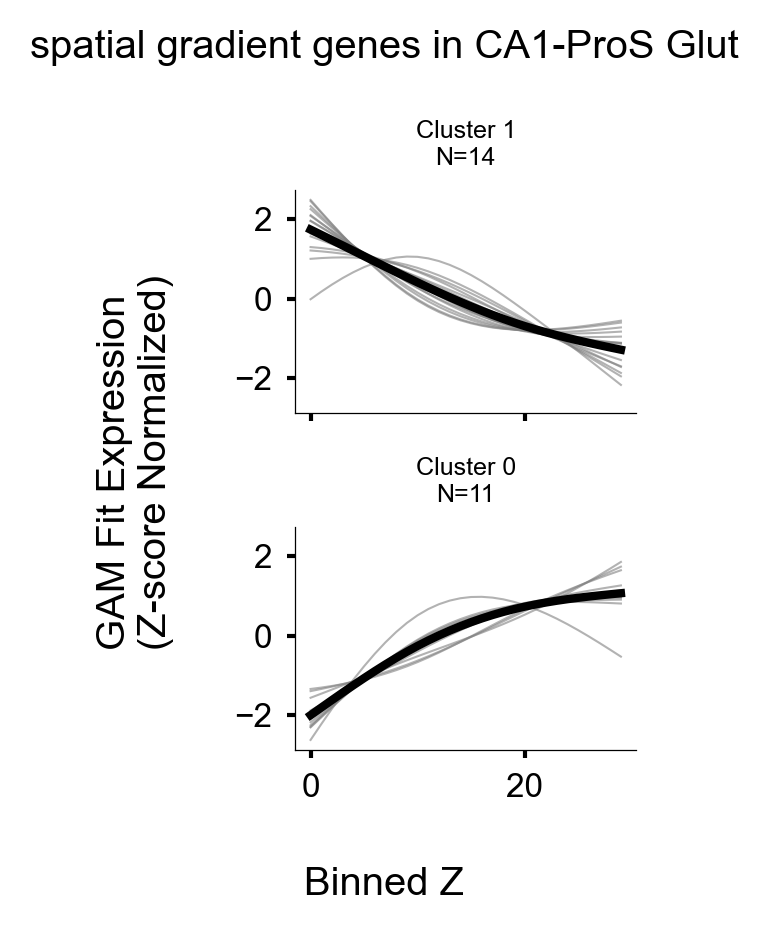

Clustering GAM fits for group: SUB-ProS Glut
Number of gene clusters: 2


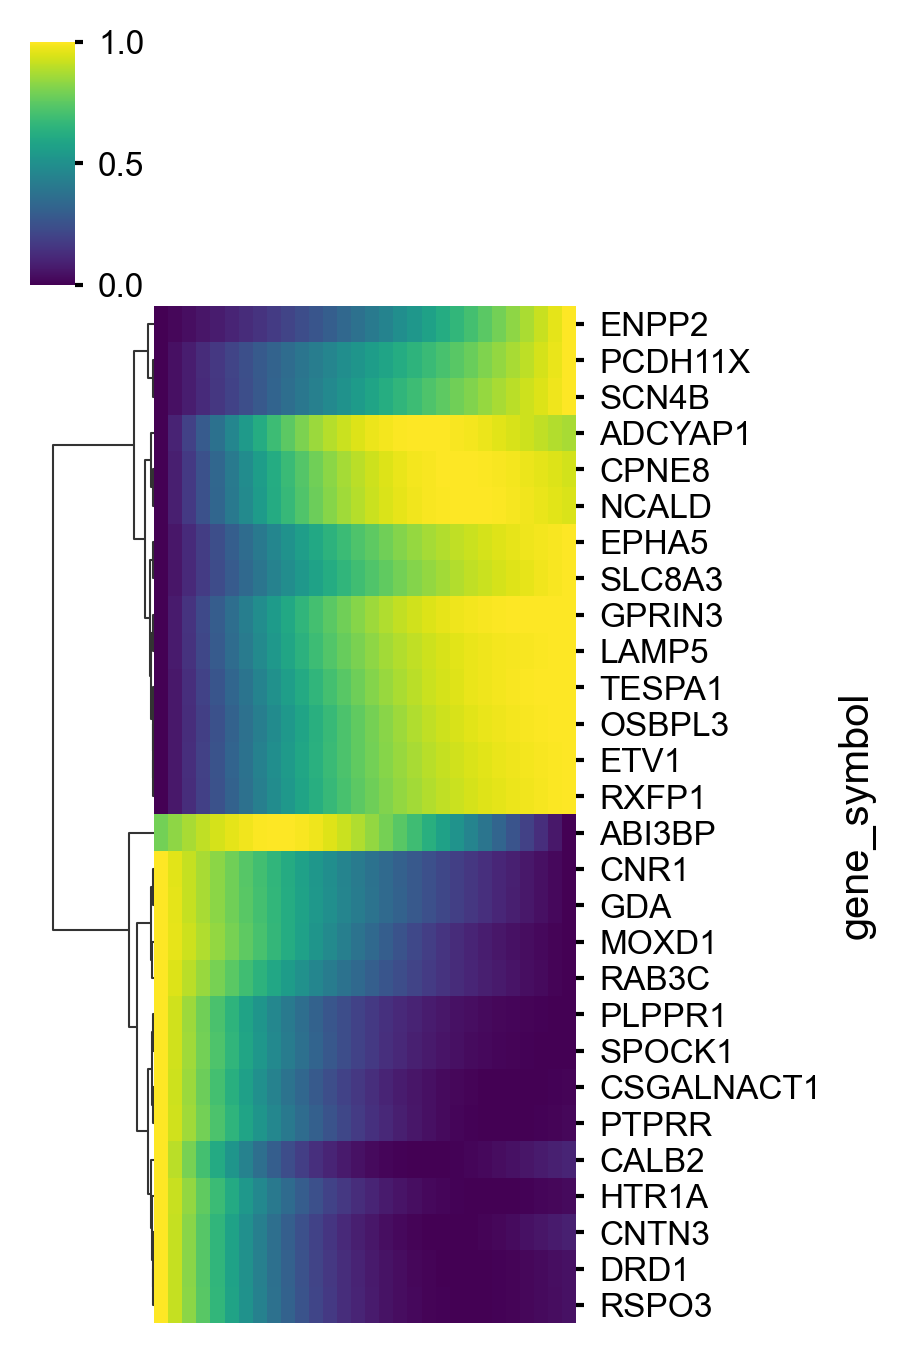

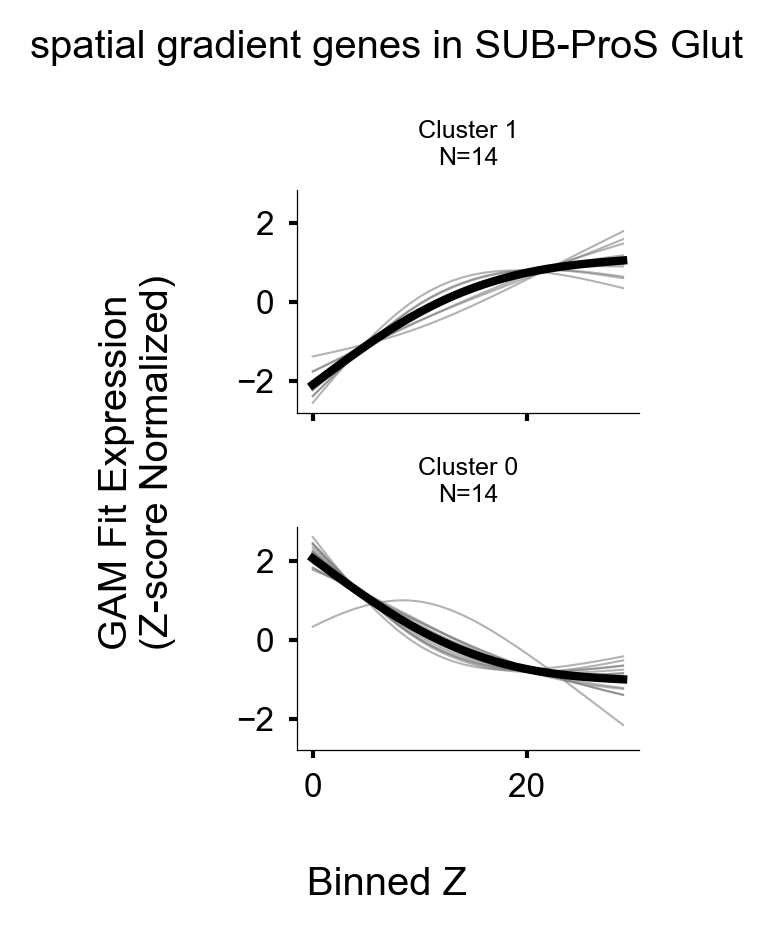

In [7]:
## cluster the GAM-fitted gene trends and plot the mean trend per cluster
spatial_filter_res = []

for group in gam_fits_dfs.keys():
    print(f"Clustering GAM fits for group: {group}")
    fits_df = gam_fits_dfs[group]

    # Hierarchical clustering
    # Remove genes with NaN values in the GAM fits
    fits_df = fits_df.dropna()
    ax = sns.clustermap(fits_df, metric='euclidean', method='ward',
                       col_cluster=False, row_cluster=True,cmap = 'viridis',
                       figsize=(3,4.5), standard_scale=0, xticklabels=False, yticklabels=True)
    dend_link = ax.dendrogram_row.linkage

    # cut dendrogram tree
    cut_tree = hierarchy.cut_tree(dend_link, height=7).squeeze()
    u_clusts = np.unique(cut_tree)
    print(f'Number of gene clusters: {len(u_clusts)}')

    spatial_filter_res.append(pd.DataFrame({
        'group': group,
        'u_clust': cut_tree,
        'gene': fits_df.index
    }))

    # Plot mean trend per cluster
    fig, ax = plt.subplots(2, 1, figsize=(2,3), sharex=True, sharey=True)
    for i, u_clust in enumerate(u_clusts[::-1]):
        ax_i = ax.flatten()[i]

        gene_indices = np.where(cut_tree == u_clust)[0]
        selected_genes = fits_df.index[gene_indices]

        # z-score normalize each gene trend before averaging
        norm_exp = fits_df.loc[selected_genes, :].apply(lambda x: (x - x.mean()) / x.std() if x.std() else 0, axis=1)
        norm_cluster_expr = norm_exp.loc[selected_genes, :]

        mean_trend = norm_cluster_expr.mean(axis=0)
        ax_i.set_title(f'Cluster {u_clust}\nN={len(selected_genes)}', fontsize=6)

        # also plot individual gene trends
        for gene in selected_genes:
            ax_i.plot(norm_cluster_expr.loc[gene, :], color='gray', alpha=0.6, linewidth=0.5)

        ax_i.plot(mean_trend, color='black', linewidth=2)
        sns.despine(ax=ax_i)

    fig.supxlabel('Binned Z')
    fig.supylabel('GAM Fit Expression\n(Z-score Normalized)')
    fig.suptitle(f'spatial gradient genes in {group}')
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / f'{group}_gam_fit_clusters.svg', format='svg', bbox_inches='tight', transparent=True, dpi=300)
    plt.show()